# ТЧМ. Лабораторна робота №2 — нестаціонарна відривна течія навколо півкола (варіант «С»)

Метод дискретних особливостей: приєднані вихори на контурі + вільні вихори сліду, що відриваються з кінців і пливуть з потоком; результат — доріжка Кармана.


**Частина A (кроки 0–4)** — основа з лаб. №1: контур, колокації, швидкість від вихору, СЛАР. Її розв'язок у момент $t = 0$ (слід порожній) — це розв'язок лаб. №1 з $\Gamma_0 = 0$.

**Частина B (кроки 5–12)** — те, що додає лаб. №2: цикл за часом (відрив вихорів, рух сліду, непроникнення для рухомих вихорів), сили $C_x$, $C_y$, тиск з $\partial\varphi/\partial t$, доріжка Кармана.

---
# Частина A. Основа з лаб. №1 (кроки 0–4)
Контур, колокації, швидкість від вихору й матриця СЛАР — майже без змін. Нове тут лише в тому, що функції швидкості та права частина СЛАР уже вміють враховувати вільні вихори сліду.

## Крок 0. Параметри

Вхідні дані дискретизованої моделі [П, §7.2.2; Сл. 4]:

$$\vec V_\infty = (u_\infty, v_\infty) = (\cos\alpha,\ \sin\alpha), \qquad |\vec V_\infty| = 1 \qquad (7.2.28)$$

$M$ — кількість дискретних особливостей на контурі.

**Як це в коді:**
| Формула | Код |
|---|---|
| $M$ | `M = 24` |
| $\alpha$ (у радіанах!) | `ALPHA` |
| $\vec V_\infty = (\cos\alpha, \sin\alpha)$ | `V_INF = np.array([np.cos(ALPHA), np.sin(ALPHA)])` |
| кінцевий час, межа видалення вихорів | `T_END`, `X_MAX` (у методичці немає — службові) |

Циркуляцію $\Gamma_0$ тут не задаємо: течія стартує зі спокою, і за теоремою Кельвіна сумарна циркуляція всіх вихорів $= 0$ [П, (6.4.45)].

In [48]:
import numpy as np
import matplotlib.pyplot as plt

M = 24                                          # кількість вихорів на контурі
ALPHA = 1                                     # кут набігаючого потоку, рад
V_INF = np.array([np.cos(ALPHA), np.sin(ALPHA)])   # |V∞| = 1
R = 0.5                                         # радіус півкола: розмір перешкоди 1
XC = R / 2                                      # центр кола: перешкода по центру
T_END = 80.0                                    # тривалість моделювання
X_MAX = 8.0                                     # далі цієї межі вихори видаляємо

## Крок 1. Контур — півколо (варіант «С»)

Контур задається впорядкованим масивом точок дискретних особливостей [П, §7.2.2; Сл. 4]:

$$\{\omega_{0j} = x_{0j} + i\,y_{0j}\},\qquad j = 1,\dots,M$$

Для півкола точки беремо з параметричного рівняння кола:

$$x_{0j} = x_C + R\cos t_j,\qquad y_{0j} = R\sin t_j,\qquad t_j \in \left[\tfrac{\pi}{2},\ \tfrac{3\pi}{2}\right]$$

Параметри для умови непроникнення в нестаціонарних задачах [П, с. 133; Сл. 15]:

$$\Delta = \frac{L}{M},\qquad \delta = \frac{L}{2M}$$

**Як це в коді:**
| Формула | Код |
|---|---|
| $t_j$ | `t = np.linspace(np.pi / 2, 3 * np.pi / 2, M)` |
| $x_{0j},\ y_{0j}$ | `x0 = XC + R * np.cos(t)`, `y0 = R * np.sin(t)` |
| $L = \pi R$ (довжина півкола) | `L = np.pi * R` |
| $\delta = L/(2M)$ | `DELTA = L / (2 * M)` |

In [49]:
t = np.linspace(np.pi / 2, 3 * np.pi / 2, M)    # параметр кожної особливості
x0 = XC + R * np.cos(t)                         # x0[j], y0[j] — точки ω0j
y0 = R * np.sin(t)
L = np.pi * R                                   # довжина контуру (півкола)
h = L / (M - 1)                                 # крок між вихорами
DELTA = L / (2 * M)                             # δ = L/(2M) [Сл. 15]

print(f"L = {L:.4f}, h = {h:.4f}, DELTA = {DELTA:.4f}")

L = 1.5708, h = 0.0683, DELTA = 0.0327


## Крок 2. Колокації та нормалі

Точки колокації — між дискретними особливостями, $k = 1,\dots,M-1$; нормалі в них [П, §7.2.2; Сл. 4]:

$$x_k = \tfrac{1}{2}(x_{0k} + x_{0k+1}),\quad y_k = \tfrac{1}{2}(y_{0k} + y_{0k+1})$$

$$n_{xk} = -\frac{y_{0k+1} - y_{0k}}{\sqrt{(x_{0k+1}-x_{0k})^2 + (y_{0k+1}-y_{0k})^2}},\qquad
n_{yk} = \frac{x_{0k+1} - x_{0k}}{\sqrt{(x_{0k+1}-x_{0k})^2 + (y_{0k+1}-y_{0k})^2}}$$

Це формули для ламаної (середини хорд). Для **гладкої дуги** беремо точки на самій дузі посередині між вихорами і точну нормаль до центру кола (як у лаб. №1):

$$t^c_k = \tfrac{1}{2}(t_k + t_{k+1}),\quad x_k = x_C + R\cos t^c_k,\quad y_k = R\sin t^c_k,\quad \vec n_k = (-\cos t^c_k,\ -\sin t^c_k)$$

**Як це в коді:**
| Формула | Код |
|---|---|
| $t^c_k$ | `tc = 0.5 * (t[:-1] + t[1:])` |
| $x_k,\ y_k$ | `xc`, `yc` |
| $\vec n_k$ | `nx = -np.cos(tc)`, `ny = -np.sin(tc)` |
| кола радіуса $\delta$ (як на [Сл. 15]) | `plt.Circle(..., DELTA, ...)` |

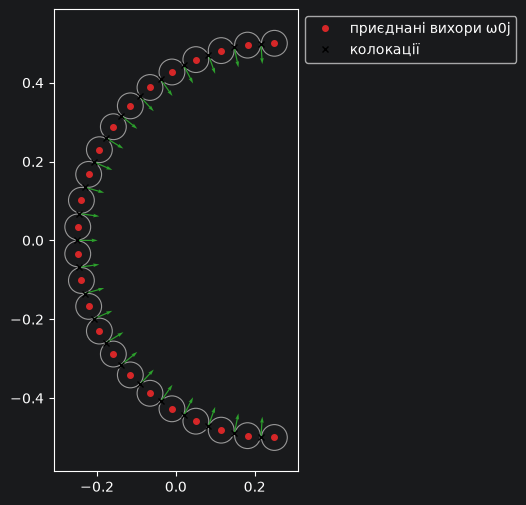

In [50]:
tc = 0.5 * (t[:-1] + t[1:])                     # параметр посередині між сусідами
xc = XC + R * np.cos(tc)                        # M-1 точок колокації на дузі
yc = R * np.sin(tc)
nx = -np.cos(tc)                                # нормаль до центру кола
ny = -np.sin(tc)                                # (= ліворуч від обходу)

fig, ax = plt.subplots(figsize=(6, 6))
for xj, yj in zip(x0, y0):                      # кола радіуса δ навколо вихорів
    ax.add_patch(plt.Circle((xj, yj), DELTA, fill=False, color="0.6", lw=0.8))
ax.plot(x0, y0, "o", color="tab:red", ms=4, label="приєднані вихори ω0j")
ax.plot(xc, yc, "x", color="k", ms=5, label="колокації")
ax.quiver(xc, yc, nx, ny, color="tab:green", scale=12, width=0.005)
ax.set_aspect("equal")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## Крок 3. Швидкість від вихорів

Швидкість у точці $(x, y)$ від вихору **одиничної** інтенсивності в точці $(x_{0i}, y_{0i})$ [П, (7.2.23)–(7.2.26); Сл. 7]:

$$u(x,y,x_{0i},y_{0i}) = \frac{1}{2\pi}\cdot\frac{y_{0i} - y}{R_{0i}^2},\qquad
v(x,y,x_{0i},y_{0i}) = \frac{1}{2\pi}\cdot\frac{x - x_{0i}}{R_{0i}^2} \qquad (7.2.24),\ (7.2.25)$$

$$R_{0i} = \max\left\{\delta,\ \sqrt{(x-x_{0i})^2 + (y-y_{0i})^2}\right\} \qquad (7.2.26)$$

Повне поле швидкості в момент $t_n$ — потік + приєднані вихори $\Gamma_j$ + вільні вихори сліду $\gamma_i^p$ [П, (7.2.22), (6.4.44)]:

$$\vec V(x,y,t_n) = \vec V_\infty + \sum_{j=1}^{M}\Gamma_j(t_n)\,\vec V(x,y,x_{0j},y_{0j}) + \sum_p\sum_{i=1}^{n}\gamma_i^p\,\vec V\big(x,y,x_i^p(t_n),y_i^p(t_n)\big) \qquad (7.2.22)$$

**Як це в коді:**
| Формула | Код |
|---|---|
| (7.2.24)–(7.2.25) | `vortex_velocity` повертає `-dy / (2π R²)`, `dx / (2π R²)` |
| $R_{0i}^2 = \max(\delta^2,\ r^2)$ (7.2.26) | `R2 = np.maximum(dx**2 + dy**2, delta**2)` |
| $\sum_i \gamma_i \vec V(\dots)$ — сума від багатьох вихорів | `induced(...)`: `U @ gs`, `V @ gs` |
| (7.2.22): $\vec V_\infty$ + контур + слід | `velocity(x, y, G, fx, fy, fg)` |

In [51]:
def vortex_velocity(x, y, x0j, y0j, delta=0.0):
    """(u, v) від вихору Γ = 1 у точці (x0j, y0j): формули (7.2.23)-(7.2.26)."""
    dx = x - x0j
    dy = y - y0j
    R2 = np.maximum(dx**2 + dy**2, delta**2)    # регуляризація: R ≥ delta
    return -dy / (2 * np.pi * R2), dx / (2 * np.pi * R2)


def induced(x, y, xs, ys, gs, delta, chunk=4000):
    """Сумарна швидкість у точках (x, y) від вихорів (xs, ys) з інтенсивностями gs."""
    u = np.zeros(len(x))
    v = np.zeros(len(x))
    for s in range(0, len(x), chunk):           # шматками, щоб не забити пам'ять
        U, V = vortex_velocity(x[s:s + chunk, None], y[s:s + chunk, None],
                               xs[None, :], ys[None, :], delta)
        u[s:s + chunk] = U @ gs
        v[s:s + chunk] = V @ gs
    return u, v


def velocity(x, y, G, fx, fy, fg):
    """Швидкість (7.2.30): потік + приєднані вихори Γj + вільні вихори сліду γi."""
    ub, vb = induced(x, y, x0, y0, G, DELTA)
    uf, vf = induced(x, y, fx, fy, fg, DELTA)
    return V_INF[0] + ub + uf, V_INF[1] + vb + vf

## Крок 4. СЛАР

Умова непроникнення в колокаціях і теорема Кельвіна дають систему для $\Gamma_1(t_{n+1}),\dots,\Gamma_M(t_{n+1})$ [П, (7.2.19)–(7.2.21), (6.4.48); Сл. 6]:

$$\sum_{j=1}^{M}\Gamma_j(t_{n+1})\big(\vec n_k\cdot\vec V_j(x_k,y_k,x_{0j},y_{0j})\big) =
-\vec n_k\cdot\vec V_\infty - \sum_p\sum_{i=1}^{n+1}\gamma_i^p\big(\vec n_k\cdot\vec V(x_k,y_k,x_i^p,y_i^p)\big),\quad k = \overline{1,M-1} \qquad (7.2.19)$$

$$\sum_{j=1}^{M}\Gamma_j(t_{n+1}) = -\sum_p\sum_{i=1}^{n+1}\gamma_i^p \qquad (7.2.20)$$

У матричному вигляді $A\,\Gamma = b$:

$$A_{kj} = \vec n_k\cdot\vec V_j(x_k,y_k),\ \ k<M;\qquad A_{Mj} = 1;\qquad
b_k = -\vec n_k\cdot(\vec V_\infty + \vec V_{\text{сліду}}),\qquad b_M = -\sum\gamma$$

**Як це в коді:**
| Формула | Код |
|---|---|
| $\vec V_j(x_k,y_k)$ для всіх пар $k, j$ | `U, V = vortex_velocity(xc[:, None], yc[:, None], x0[None, :], y0[None, :])` |
| $A_{kj} = \vec n_k\cdot\vec V_j$ — ліва частина (7.2.19) | `A[:-1] = nx[:, None] * U + ny[:, None] * V` |
| $A_{Mj} = 1$ — ліва частина (7.2.20) | `A[-1] = 1.0` |
| $\vec V_{\text{сліду}}$ у колокаціях | `uf, vf = induced(xc, yc, fx, fy, fg, DELTA)` |
| права частина (7.2.19) | `b[:-1] = -(nx * (V_INF[0] + uf) + ny * (V_INF[1] + vf))` |
| права частина (7.2.20): $-\sum\gamma$ | `b[-1] = -shed_total` |
| розв'язок (7.2.21) | `A_inv @ b` (матриця не змінюється в часі — обертаємо один раз) |

Перевірка: при порожньому сліді $\sum\Gamma_j \approx 0$ і $\max_k|\vec V\cdot\vec n_k| \approx 0$.

In [52]:
# Матриця СЛАР залежить лише від геометрії контуру, тож будуємо її один раз
U, V = vortex_velocity(xc[:, None], yc[:, None], x0[None, :], y0[None, :])
A = np.empty((M, M))
A[:-1] = nx[:, None] * U + ny[:, None] * V      # ліва частина (7.2.19)
A[-1] = 1.0                                     # ліва частина (7.2.20)
A_inv = np.linalg.inv(A)


def solve_gammas(fx, fy, fg, shed_total):
    """Γ1..ΓM на новому кроці за (7.2.19)-(7.2.20).

    shed_total — сума інтенсивностей усіх вихорів, що відірвались від контуру.
    """
    uf, vf = induced(xc, yc, fx, fy, fg, DELTA)  # швидкість від сліду в колокаціях
    b = np.empty(M)
    b[:-1] = -(nx * (V_INF[0] + uf) + ny * (V_INF[1] + vf))
    b[-1] = -shed_total                          # повна циркуляція = 0 (Кельвін)
    return A_inv @ b


empty = np.empty(0)
G = solve_gammas(empty, empty, empty, 0.0)      # t = t0: сліду ще немає
u_c, v_c = velocity(xc, yc, G, empty, empty, empty)
print(f"sum Γ = {G.sum():.2e}, max|V·n| = {np.abs(u_c * nx + v_c * ny).max():.1e}")

sum Γ = 2.78e-16, max|V·n| = 3.6e-16


---
# Частина B. Нове в лаб. №2: нестаціонарна відривна течія (кроки 5–12)
Обгортаємо розв'язання СЛАР у **цикл за часом**: на кожному кроці кінцеві вихори відриваються, слід зсувається з потоком, вихори, що проскочили крізь контур, повертаються, і СЛАР розв'язується заново. Далі — аналіз: слід, сили й режими, поля, анімація.

## Крок 5. Непроникнення для рухомих вихорів

Вільний вихор не повинен перетинати контур. Бік контуру, з якого знаходиться точка, визначають знаком векторного добутку [П, §7.2.4; Сл. 16]:

$$\operatorname{sign}(\vec R_1\times\vec R_2) > 0\ \Rightarrow\ r\in D^+,\qquad \operatorname{sign}(\vec R_1\times\vec R_2) < 0\ \Rightarrow\ r\in D^-$$

Навколо контуру — заборонена смуга $\Delta = 2\delta$ [Сл. 15]; точку, що потрапила в неї або перетнула контур, повертають на свій бік (рис. 7.2.16, варіант D — дзеркально).

Для **дуги кола** бік визначає відстань до центру $r = |\vec r - \vec r_C|$: зовні $r > R$, усередині $r < R$. Порушника відбиваємо вздовж радіуса:

$$r_{\text{нове}} = R + s\cdot\max\big(|r - R|,\ \delta\big),\qquad s = \begin{cases}+1, & \text{вихор був зовні}\\ -1, & \text{був у «чаші»}\end{cases}$$

**Як це в коді:**
| Формула | Код |
|---|---|
| бік до кроку $s$ | `side = np.where(r_old >= R, 1.0, -1.0)` |
| $r - R$ після кроку | `gap = r_new - R` |
| перетнув дугу або ближче за $\delta$ | `bad = on_arc & ((np.sign(gap) != side) \| (np.abs(gap) < DELTA))` |
| $r_{\text{нове}}$ | `r_fix = R + side * np.maximum(np.abs(gap), DELTA)` |

In [53]:
def keep_out(x_old, y_old, x_new, y_new):
    """Непроникнення для рухомих вихорів (§7.2.4): не пускаємо їх крізь дугу.

    Вихор, що перетнув дугу або підійшов до неї ближче за DELTA, повертаємо
    на свій бік контуру на відстань не меншу за DELTA (відбиття по радіусу).
    """
    r_old = np.hypot(x_old - XC, y_old)
    r_new = np.hypot(x_new - XC, y_new)
    side = np.where(r_old >= R, 1.0, -1.0)      # +1 — зовні кола, -1 — у «чаші»
    gap = r_new - R                             # відстань до кола зі знаком
    on_arc = x_new - XC <= 0                    # дуга займає ліву половину кола
    bad = on_arc & ((np.sign(gap) != side) | (np.abs(gap) < DELTA))
    r_fix = R + side * np.maximum(np.abs(gap), DELTA)
    k = np.where(bad, r_fix / np.maximum(r_new, 1e-12), 1.0)
    return XC + (x_new - XC) * k, y_new * k

## Крок 6. Один крок за часом

Послідовність кроків при моделюванні кінематики [П, (7.2.28)–(7.2.36), §6.5.1 етапи I–IV; Сл. 8–10].

**1) Відрив.** Кінцеві вихори контуру стають вільними (гіпотеза Кутта–Жуковського [П, §5.1–5.2]):

$$\gamma^p_{n+1} = \Gamma_p(t_n),\qquad p \in \{1,\ M\}$$

**2) Швидкості всіх вільних вихорів** у момент $t_n$ [П, (7.2.31)]:

$$\vec V(x,y,t_n) = \vec V_\infty + \sum_{j=1}^{M}\Gamma_j(t_n)\vec V(x,y,x_{0j},y_{0j}) + \sum_p\sum_{i=1}^{n}\gamma_i^p\vec V\big(x,y,x_i^p(t_n),y_i^p(t_n)\big) \qquad (7.2.31)$$

**3) Крок за часом** [П, (7.2.27)]:

$$\tau_n = \frac{\min_k \delta_k}{\max_{D^+}|\vec V|} \qquad (7.2.27)$$

**4) Пересування за час $\Delta t = t_{n+1} - t_n$** [П, (7.2.15), (7.2.32)]:

$$x_i^p(t_{n+1}) = x_i^p(t_n) + u\big(x_i^p(t_n), y_i^p(t_n), t_n\big)(t_{n+1}-t_n),\qquad
y_i^p(t_{n+1}) = y_i^p(t_n) + v\big(\dots\big)(t_{n+1}-t_n) \qquad (7.2.32)$$

**5) Нова СЛАР** (7.2.33)–(7.2.34) $\Rightarrow \Gamma_j(t_{n+1})$ — крок 4.

**Як це в коді (`time_step`):**
| Формула | Код |
|---|---|
| $\gamma^p_{n+1} = \Gamma_p(t_n)$ | `pg = np.append(fg, [G[0], G[-1]])`, точки — `[x0[0], x0[-1]]` |
| (7.2.31) | `u, v = velocity(px, py, G, fx, fy, fg)` |
| (7.2.27) | `dt = DELTA / np.max(np.hypot(u, v))` |
| (7.2.32) + непроникнення | `keep_out(px, py, px + u * dt, py + v * dt)` |
| $\sum\gamma$ для (7.2.20) | `shed_total += G[0] + G[-1]` |
| (7.2.33)–(7.2.34) | `G = solve_gammas(px, py, pg, shed_total)` |

`impulse` — для сил у кроці 7: $\vec P/\rho = \sum_k \Gamma_k\,(y_k,\ -x_k)$ по всіх вихорах (формули в методичці немає; див. гайд, розд. «Сили…»).

In [54]:
def time_step(G, fx, fy, fg, shed_total):
    """Один крок t_n -> t_n+1 за (7.2.28)-(7.2.36)."""

    # 1) кінцеві вихори відриваються: γ^p_{n+1} = Γ_p(t_n), p = 1 і M
    px = np.append(fx, [x0[0], x0[-1]])
    py = np.append(fy, [y0[0], y0[-1]])
    pg = np.append(fg, [G[0], G[-1]])

    # 2) швидкості всіх вільних вихорів у момент t_n (7.2.31)
    u, v = velocity(px, py, G, fx, fy, fg)
    dt = DELTA / np.max(np.hypot(u, v))         # крок за часом (7.2.27)

    # 3) пересування (7.2.32) і непроникнення для рухомих точок
    px, py = keep_out(px, py, px + u * dt, py + v * dt)
    shed_total += G[0] + G[-1]

    # 4) нові Γ1..ΓM із СЛАР (7.2.33)-(7.2.34)
    G = solve_gammas(px, py, pg, shed_total)
    return G, px, py, pg, shed_total, dt


def impulse(G, fx, fy, fg):
    """Гідродинамічний імпульс системи вихорів (ділений на ρ): Σ Γ (y, -x)."""
    return np.array([G @ y0 + fg @ fy, -(G @ x0) - fg @ fx])

## Крок 7. Головний цикл

Етапи I–VI [П, §6.5.1] повторюються: після кроку все відомо в момент $t_{n+1}$, і це знову етап I. Початкова умова — слід порожній [П, (7.2.6)]:

$$t = t_0:\quad L_0 = L_d(t_0) + L_v(t_0),\qquad L_v(t_0) = \varnothing$$

Сили (не з методички — гідродинамічний імпульс, Wu 1981):

$$\vec P = \rho\sum_k\Gamma_k\,(y_k,\ -x_k),\qquad \vec F = -\frac{d\vec P}{dt},\qquad C_{x,y} = \frac{F_{x,y}}{\rho V_\infty^2 D/2}$$

**Як це в коді:**
| Формула | Код |
|---|---|
| $L_v(t_0) = \varnothing$ | `fx, fy, fg = np.empty(0), ...` |
| цикл етапів до $T$ | `while time_now < T_END: ... time_step(...)` |
| $C = -2\,\Delta P/\tau$ (при $\rho = V_\infty = D = 1$) | `Cx, Cy = -2 * (P - P_old) / dt` |
| запис результатів | `history.append(...)`, `frames.append(...)` |

In [55]:
fx, fy, fg = np.empty(0), np.empty(0), np.empty(0)   # слід: координати та γ
shed_total = 0.0
time_now = 0.0
history = []                                    # рядки (t, Cx, Cy, кількість вихорів)
frames = []                                     # кадри для рисунків і анімації
FRAME_DT = 0.5
P_old = impulse(G, fx, fy, fg)

while time_now < T_END:
    G, fx, fy, fg, shed_total, dt = time_step(G, fx, fy, fg, shed_total)
    time_now += dt
    P = impulse(G, fx, fy, fg)
    Cx, Cy = -2 * (P - P_old) / dt              # F = -ρ dP/dt, C = F / (ρ V∞² D / 2)
    history.append((time_now, Cx, Cy, len(fg)))
    far = fx > X_MAX                            # видаляємо вихори, що відлетіли
    P -= impulse(np.zeros(M), fx[far], fy[far], fg[far])
    fx, fy, fg = fx[~far], fy[~far], fg[~far]
    P_old = P
    if time_now >= len(frames) * FRAME_DT:
        frames.append((time_now, G.copy(), fx.copy(), fy.copy(), fg.copy()))
    if len(history) % 500 == 0:
        print(f"крок {len(history)}: t = {time_now:.1f}, вихорів {len(fg)}")

history = np.array(history)
print(f"готово: {len(history)} кроків, t = {time_now:.2f}, вихорів у сліді {len(fg)}")

крок 500: t = 10.2, вихорів 1000
крок 1000: t = 20.0, вихорів 1618
крок 1500: t = 24.3, вихорів 2382
крок 2000: t = 29.3, вихорів 3052
крок 2500: t = 30.5, вихорів 4029
крок 3000: t = 32.6, вихорів 4583
крок 3500: t = 36.6, вихорів 4616
крок 4000: t = 41.2, вихорів 4120
крок 4500: t = 43.7, вихорів 4665
крок 5000: t = 44.8, вихорів 5428
крок 5500: t = 47.5, вихорів 5937


KeyboardInterrupt: 

## Крок 8. Вихровий слід

Малюємо вільну межу $L_v(t)$ — усі вільні вихори $(x_i^p(t), y_i^p(t))$ з інтенсивностями $\gamma_i^p$ — у кілька моментів часу, як на рис. 7.2.10 [П] і [Сл. 13].

Колір — знак $\gamma_i^p$: $\gamma < 0$ — обертання за годинниковою стрілкою (синій), $\gamma > 0$ — проти (червоний).

**Як це в коді:** `ax.scatter(fxf, fyf, c=np.sign(fgf), cmap="bwr")` для кадрів $t = 5, 20, 40, T$.

In [ ]:
def frame_at(t_want):
    """Кадр, найближчий до заданого моменту часу."""
    return min(frames, key=lambda f: abs(f[0] - t_want))


fig, axes = plt.subplots(4, 1, figsize=(10, 11), sharex=True)
for ax, t_want in zip(axes, [5, 20, 40, T_END]):
    tf, Gf, fxf, fyf, fgf = frame_at(t_want)
    ax.scatter(fxf, fyf, s=3, c=np.sign(fgf), cmap="bwr", vmin=-1, vmax=1)
    ax.plot(x0, y0, "k-", lw=2)
    ax.set_aspect("equal")
    ax.set_xlim(-0.5, X_MAX)
    ax.set_ylim(-1.6, 1.6)
    ax.set_title(f"t = {tf:.1f}")
fig.suptitle("Вільні вихори: синій — γ < 0 (за год. стрілкою), червоний — γ > 0")
plt.show()

## Крок 9. Сили і режими течії

Графік $C_x(t)$, $C_y(t)$ — «інтегральні характеристики навантажень», за якими визначають режими течії I–IV [П, §7.2.5, рис. 7.2.20; Сл. 18].

Число Струхаля — безрозмірна частота відриву вихорів:

$$\mathrm{St} = \frac{f\,D}{V_\infty}$$

де $f$ — частота коливань $C_y$ у режимі IV.

**Як це в коді:**
| Формула | Код |
|---|---|
| $C_x(t),\ C_y(t)$ з кроку 7 | `history[:, 1]`, `history[:, 2]` |
| частота $f$ — пік спектра $C_y$ | `np.fft.rfft(...)`, `freq[np.argmax(spec[1:]) + 1]` |
| $\mathrm{St} = f$ (бо $D = V_\infty = 1$) | `f_main` |

In [ ]:
tt, Cx, Cy = history[:, 0], history[:, 1], history[:, 2]
k = 15                                          # згладжування ковзним середнім
smooth = lambda a: np.convolve(a, np.ones(k) / k, mode="same")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(tt, smooth(Cx), color="tab:red", label="Cx (опір)")
ax.plot(tt, smooth(Cy), color="tab:blue", label="Cy (бокова сила)")
ax.set_xlabel("t")
ax.set_ylim(-4, 5)
ax.grid(alpha=0.3)
ax.legend()
plt.show()

late = tt > T_END / 2                           # усталений періодичний режим
spec = np.abs(np.fft.rfft(Cy[late] - Cy[late].mean()))
freq = np.fft.rfftfreq(late.sum(), d=np.mean(np.diff(tt[late])))
f_main = freq[np.argmax(spec[1:]) + 1]
print(f"середній Cx = {Cx[late].mean():.2f}, Струхаль St = f·D/V∞ = {f_main:.3f}")

## Крок 10. Поля швидкості, потенціалу і тиску

**Потенціал** [П, (7.2.38), (6.4.42); Сл. 11 (46)]:

$$\varphi(x,y,t) = x\cos\alpha + y\sin\alpha + \sum_{j=1}^{M}\frac{\Gamma_j(t)}{2\pi}\,\mathrm{Arctg}\frac{y - y_{0j}}{x - x_{0j}} + \sum_p\sum_{i=1}^{n(t)}\frac{\gamma_i^p}{2\pi}\,\mathrm{Arctg}\frac{y - y_i^p(t)}{x - x_i^p(t)}$$

де $\mathrm{Arctg}$ — круговий арктангенс, тобто $\arg(z-\omega_0) \in [0, 2\pi)$. У коді зручніше $\theta = \arg(z-\omega_0)/2\pi \in [0,1)$ (7.1.14), тоді $\frac{\Gamma}{2\pi}\mathrm{Arctg} = \Gamma\,\theta$.

**Коефіцієнт тиску** з інтеграла Коші–Лагранжа [П, (7.2.39), (6.4.51); Сл. 11 (47)]:

$$C_p(x,y,t) = 2\,\frac{p - p_\infty}{\rho V_\infty^2} = 1 - \frac{(\nabla\varphi)^2}{V_\infty^2} - \frac{2}{V_\infty^2}\frac{\partial\varphi}{\partial t} \qquad (7.2.39)$$

**Похідна $\partial\varphi/\partial t$ без розрізів** [П, §6.5.2, (6.5.1)–(6.5.7)]: за теоремою Кельвіна $\sum_j\dot\Gamma_j = -\sum_p\dot\gamma^p_n$ (6.5.4), тому зміну інтенсивностей переписуємо як диполі:

$$\sum_j \Delta\Gamma_j\,\theta_j = \sum_{j=1}^{M-1} S_j\,(\theta_j - \theta_{j+1}) + S_M\theta_M,\qquad S_j = \sum_{k\le j}\Delta\Gamma_k,\quad S_M = 0$$

**Як це в коді:**
| Формула | Код |
|---|---|
| $\theta = \arg(z-\omega_0)/2\pi \in [0, 1)$ | `theta(x, y, xs, ys)` |
| $\varphi$ (7.2.38) | `phi_field(X, Y, G, fx, fy, fg)` |
| різниця кутів без стрибка на оберт | `wrap(a) = a - np.round(a)` |
| $S_j = \sum_{k\le j}\Delta\Gamma_k$ | `S = np.cumsum(dB)` |
| $\partial\varphi/\partial t \approx \Delta\varphi/\tau$ | `dphi_dt(...)` (+ ще один `time_step`) |
| $\vert \vec V\vert $ | `speed = np.hypot(u, v)` |
| (7.2.39) при $V_\infty = 1$ | `Cp = 1 - speed**2 - 2 * dphi_dt(...)` |

In [ ]:
def theta(x, y, xs, ys):
    """Круговий арктангенс (7.1.14): arg(z - ω) / 2π у межах [0, 1)."""
    return np.mod(np.arctan2(y - ys, x - xs), 2 * np.pi) / (2 * np.pi)


def wrap(a):
    """Приводить різницю кутів (у частках 2π) до (-1/2, 1/2]: прибирає стрибки."""
    return a - np.round(a)


def phi_field(X, Y, G, fx, fy, fg):
    """Потенціал (7.2.38): потік + приєднані вихори + вільні вихори."""
    phi = X * V_INF[0] + Y * V_INF[1]
    for xs, ys, g in zip(np.r_[x0, fx], np.r_[y0, fy], np.r_[G, fg]):
        phi += g * theta(X, Y, xs, ys)
    return phi


def dphi_dt(X, Y, G0, fx0, fy0, G1, fx1, fy1, fg1, dt):
    """∂φ/∂t між кроками n і n+1 (без розрізів, див. гайд)."""
    ox = np.r_[fx0, x0[0], x0[-1]]              # де кожен вільний вихор був на кроці n
    oy = np.r_[fy0, y0[0], y0[-1]]              # (новонароджені — на кінцях контуру)
    d = np.zeros_like(X)
    for i in range(len(fg1)):
        d += fg1[i] * wrap(theta(X, Y, fx1[i], fy1[i]) - theta(X, Y, ox[i], oy[i]))
    dB = G1 - G0
    dB[[0, -1]] = G1[[0, -1]]                   # кінцеві Γ на кроці n стали вільними
    S = np.cumsum(dB)                           # S_M = 0 за теоремою Кельвіна
    for j in range(M - 1):
        d += S[j] * wrap(theta(X, Y, x0[j], y0[j]) - theta(X, Y, x0[j + 1], y0[j + 1]))
    return d / dt


X, Y = np.meshgrid(np.linspace(-1, 4, 300), np.linspace(-1.5, 1.5, 180))
xs_, ys_ = X.ravel(), Y.ravel()
u, v = velocity(xs_, ys_, G, fx, fy, fg)
u, v = u.reshape(X.shape), v.reshape(X.shape)
speed = np.hypot(u, v)
phi = phi_field(X, Y, G, fx, fy, fg)
# ще один крок, щоб оцінити ∂φ/∂t
G1, fx1, fy1, fg1, _, dt1 = time_step(G, fx, fy, fg, shed_total)
Cp = 1 - speed**2 - 2 * dphi_dt(X, Y, G, fx, fy, G1, fx1, fy1, fg1, dt1)   # (7.2.39)
print(f"Cp перед перешкодою (x = -0.3, y = 0): {Cp[90, 42]:.2f}")

## Крок 11. Чотири графіки полів

Приклади графічного відображення [П, §7.2.3, рис. 7.2.5; Сл. 11–12]:

1. векторне поле $\vec V(x,y,t)$ (7.2.37) на тлі $|\vec V|$;
2. ізолінії $|\vec V| = \mathrm{const}$;
3. ізолінії $\varphi(x,y,t) = \mathrm{const}$ (7.2.38);
4. ізолінії $C_p(x,y,t) = \mathrm{const}$ (7.2.39).

**Як це в коді:** `imshow` + `quiver` — графік 1; `contourf` для `speed`, `phi`, `Cp` — графіки 2–4; сірі точки — вільні вихори `fx, fy`.

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8.5))
ext = (X.min(), X.max(), Y.min(), Y.max())
s = 8                                           # стрілка в кожній 8-й точці сітки
ax[0, 0].imshow(speed, extent=ext, origin="lower", cmap="Blues", vmax=2.5)
ax[0, 0].quiver(X[::s, ::s], Y[::s, ::s], (u / speed)[::s, ::s], (v / speed)[::s, ::s],
                scale=45, width=0.002)
ax[0, 0].set_title("1) векторне поле V на тлі |V|")

panels = [(ax[0, 1], speed, "2) |V| = const", "Blues", (0, 2.5)),
          (ax[1, 0], phi, "3) φ = const", "RdBu_r", np.percentile(phi, [2, 98])),
          (ax[1, 1], Cp, "4) Cp = const", "RdBu_r", (-3, 1))]
for a, F, title, cmap, (lo, hi) in panels:
    levels = np.linspace(lo, hi, 26)
    cs = a.contourf(X, Y, F, levels=levels, cmap=cmap, extend="both")
    fig.colorbar(cs, ax=a)
    a.set_title(title)

for a in ax.flat:
    a.plot(x0, y0, "k-", lw=2)
    a.plot(fx, fy, ".", color="0.3", ms=1)
    a.set_xlim(X.min(), X.max())
    a.set_ylim(Y.min(), Y.max())
    a.set_aspect("equal")
fig.suptitle(f"t = {time_now:.1f}, M = {M}")
plt.show()

## Крок 12. Анімація розвитку сліду

Покадрово показуємо розвиток вільної межі $L_v(t)$ — від стартового режиму до доріжки Кармана [П, рис. 7.2.10, 7.2.18; Сл. 13, 17].

**Як це в коді:** `FuncAnimation` перемальовує точки `(fx, fy)` з кадрів `frames`; кнопка ▶ під рисунком.

In [ ]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(x0, y0, "k-", lw=2)
dots = ax.scatter([], [], s=3, c=[], cmap="bwr", vmin=-1, vmax=1)
label = ax.set_title("")
ax.set_aspect("equal")
ax.set_xlim(-0.5, X_MAX)
ax.set_ylim(-1.6, 1.6)


def draw(i):
    tf, _, fxf, fyf, fgf = frames[i]
    dots.set_offsets(np.c_[fxf, fyf])
    dots.set_array(np.sign(fgf))
    label.set_text(f"t = {tf:.1f}")
    return dots, label


anim = FuncAnimation(fig, draw, frames=len(frames), interval=60)
plt.close(fig)
HTML(anim.to_jshtml())